# 🔮 GridForecast — 04: Prophet

**Цел:** Prophet модел с multiple seasonalities + external regressors.

**Ключови решения (след diagnostics):**
- `growth="flat"` — consumption няма дългосрочен растящ trend
- `seasonality_mode="additive"` — избягваме compounding ефект
- `yearly_seasonality=True` — годишният цикъл е реален (независимо от warning)
- `temperature_c` като additive regressor
- `is_weekend`/`is_holiday` като additive binary regressors

**История на експериментите:**
- v1 (broken): linear + multiplicative + no yearly → **83% MAPE** ❌
- v1 (fixed): flat + additive + yearly → **8.03%** ✅
- v2: + temperature → **8.01%** ✅
- v3: + weekend + holiday → **6.84%** 🏆
- v4: linear + small changepoint → **29.06%** ❌
- v5: yearly='auto' → **18.02%** ❌

**Заключение:** `growth="flat"` + `yearly=True` е правилната комбинация.

**Структура:**
1. Setup
2. Load + train/test split
3. Prepare Prophet формат
4. Prophet v1 — default + seasonalities
5. Prophet v2 — + temperature
6. Prophet v3 — + weekend + holiday 🏆
7. Сравнение + bar chart
8. Визуализация
9. Components
10. Diagnostics
11. Save best model
12. Заключение

## 1️⃣ Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from prophet import Prophet
from prophet.plot import plot_components

from sklearn.metrics import mean_absolute_error, mean_squared_error

from gridforecast.config import (
    SYNTHETIC_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    FORECAST_HORIZON_HOURS,
    TRAIN_RATIO,
    RANDOM_SEED,
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)

print("✅ Imports OK")

✅ Imports OK


## 2️⃣ Load + train/test split

In [2]:
df = pd.read_parquet(SYNTHETIC_DIR / "consumption_stable.parquet")
df.index = pd.DatetimeIndex(df.index)

split_idx = int(TRAIN_RATIO * len(df))
train = df.iloc[:split_idx]
test = df.iloc[split_idx:]

y_test = test["consumption_mw"]
y_full = df["consumption_mw"].values

# Baseline: Seasonal Naive (24h lag)
y_pred_snaive = y_full[split_idx - 24 : split_idx - 24 + len(test)]


def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


baseline_mape = mape(y_test.values, y_pred_snaive)
print(f"Train: {len(train):,} | Test: {len(test):,}")
print(f"Baseline (Seasonal Naive) MAPE: {baseline_mape:.2f}%")
print(f"Snaive len: {len(y_pred_snaive)} | Test len: {len(y_test)}")

Train: 14,016 | Test: 3,504
Baseline (Seasonal Naive) MAPE: 9.20%
Snaive len: 3504 | Test len: 3504


## 3️⃣ Prepare data за Prophet (ds, y формат)

In [3]:
def prepare_prophet_df(d):
    out = pd.DataFrame({
        "ds": d.index,
        "y": d["consumption_mw"].values,
        "temperature_c": d["temperature_c"].values,
        "is_weekend": d["is_weekend"].astype(int).values,
        "is_holiday": d["is_holiday"].astype(int).values,
    })
    return out


train_p = prepare_prophet_df(train)
test_p = prepare_prophet_df(test)

print(f"Train shape: {train_p.shape}")
print(f"Test shape:  {test_p.shape}")
train_p.head()

Train shape: (14016, 5)
Test shape:  (3504, 5)


,ds,y,temperature_c,is_weekend,is_holiday
0,2023-01-01 00:00:00,971.407629,-0.617696,1,1
1,2023-01-01 01:00:00,1023.915710,-4.101691,1,1
2,2023-01-01 02:00:00,972.499609,-1.020323,1,1
3,2023-01-01 03:00:00,971.443062,-0.810467,1,1
4,2023-01-01 04:00:00,1092.938705,-6.423295,1,1


## 4️⃣ Prophet v1 — default + seasonalities

**Ключови параметри:**
- `growth="flat"` — Prophet няма да extrapolate-ва trend
- `seasonality_mode="additive"` — yhat = trend + weekly + daily + yearly
- `yearly_seasonality=True` — годишният цикъл е реален (warning-ът е информативен)

In [4]:
print("Fitting Prophet v1...")

model_v1 = Prophet(
    growth="flat",
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True,
    seasonality_mode="additive",
)

model_v1.fit(train_p[["ds", "y"]])

future_v1 = model_v1.make_future_dataframe(periods=len(test_p), freq="h")
forecast_v1 = model_v1.predict(future_v1)
y_pred_v1 = forecast_v1.iloc[-len(test_p):]["yhat"].values

mape_v1 = mape(y_test.values, y_pred_v1)
mae_v1 = mean_absolute_error(y_test.values, y_pred_v1)
rmse_v1 = np.sqrt(mean_squared_error(y_test.values, y_pred_v1))

print(f"\nProphet v1:")
print(f"  MAE:  {mae_v1:.1f} MW")
print(f"  RMSE: {rmse_v1:.1f} MW")
print(f"  MAPE: {mape_v1:.2f}%")
print(f"  Pred mean: {y_pred_v1.mean():.1f} | Actual mean: {y_test.mean():.1f}")

Fitting Prophet v1...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
21:39:40 - cmdstanpy - INFO - Chain [1] start processing
21:39:40 - cmdstanpy - INFO - Chain [1] done processing



Prophet v1:
  MAE:  79.1 MW
  RMSE: 107.1 MW
  MAPE: 8.03%
  Pred mean: 1022.6 | Actual mean: 1013.3


## 5️⃣ Prophet v2 — + temperature regressor (additive)

In [5]:
print("Fitting Prophet v2 (+ temperature)...")

model_v2 = Prophet(
    growth="flat",
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True,
    seasonality_mode="additive",
)

model_v2.add_regressor("temperature_c", mode="additive")

model_v2.fit(train_p[["ds", "y", "temperature_c"]])

future_v2 = model_v2.make_future_dataframe(periods=len(test_p), freq="h")
future_v2["temperature_c"] = np.concatenate([
    train_p["temperature_c"].values,
    test_p["temperature_c"].values,
])

forecast_v2 = model_v2.predict(future_v2)
y_pred_v2 = forecast_v2.iloc[-len(test_p):]["yhat"].values

mape_v2 = mape(y_test.values, y_pred_v2)
mae_v2 = mean_absolute_error(y_test.values, y_pred_v2)
rmse_v2 = np.sqrt(mean_squared_error(y_test.values, y_pred_v2))

print(f"\nProphet v2:")
print(f"  MAE:  {mae_v2:.1f} MW")
print(f"  RMSE: {rmse_v2:.1f} MW")
print(f"  MAPE: {mape_v2:.2f}%")
print(f"  Pred mean: {y_pred_v2.mean():.1f} | Actual mean: {y_test.mean():.1f}")

Fitting Prophet v2 (+ temperature)...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
21:39:42 - cmdstanpy - INFO - Chain [1] start processing
21:39:42 - cmdstanpy - INFO - Chain [1] done processing



Prophet v2:
  MAE:  79.0 MW
  RMSE: 106.9 MW
  MAPE: 8.01%
  Pred mean: 1022.7 | Actual mean: 1013.3


## 6️⃣ Prophet v3 — + weekend + holiday (additive binary regressors) 🏆

In [6]:
print("Fitting Prophet v3 (+ weekend + holiday)...")

model_v3 = Prophet(
    growth="flat",
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True,
    seasonality_mode="additive",
)

model_v3.add_regressor("temperature_c", mode="additive")
model_v3.add_regressor("is_weekend", mode="additive")
model_v3.add_regressor("is_holiday", mode="additive")

model_v3.fit(train_p[["ds", "y", "temperature_c", "is_weekend", "is_holiday"]])

future_v3 = model_v3.make_future_dataframe(periods=len(test_p), freq="h")
future_v3["temperature_c"] = np.concatenate([
    train_p["temperature_c"].values,
    test_p["temperature_c"].values,
])
future_v3["is_weekend"] = np.concatenate([
    train_p["is_weekend"].values,
    test_p["is_weekend"].values,
])
future_v3["is_holiday"] = np.concatenate([
    train_p["is_holiday"].values,
    test_p["is_holiday"].values,
])

forecast_v3 = model_v3.predict(future_v3)
y_pred_v3 = forecast_v3.iloc[-len(test_p):]["yhat"].values

mape_v3 = mape(y_test.values, y_pred_v3)
mae_v3 = mean_absolute_error(y_test.values, y_pred_v3)
rmse_v3 = np.sqrt(mean_squared_error(y_test.values, y_pred_v3))

print(f"\nProphet v3:")
print(f"  MAE:  {mae_v3:.1f} MW")
print(f"  RMSE: {rmse_v3:.1f} MW")
print(f"  MAPE: {mape_v3:.2f}%")
print(f"  Pred mean: {y_pred_v3.mean():.1f} | Actual mean: {y_test.mean():.1f}")

Fitting Prophet v3 (+ weekend + holiday)...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
21:39:44 - cmdstanpy - INFO - Chain [1] start processing
21:39:44 - cmdstanpy - INFO - Chain [1] done processing



Prophet v3:
  MAE:  69.0 MW
  RMSE: 90.4 MW
  MAPE: 6.84%
  Pred mean: 1022.5 | Actual mean: 1013.3


## 7️⃣ Сравнение + bar chart

                         model       MAE       RMSE     MAPE
          Prophet v1 (default) 79.145808 107.068276 8.028935
            Prophet v2 (+temp) 78.970421 106.871661 8.005979
Prophet v3 (+temp+weekend+hol) 69.043492  90.427572 6.841115
     Seasonal Naive (baseline) 91.185109 121.829530 9.203856
           SARIMA v2 (from 03) 98.300000 128.700000 8.070000


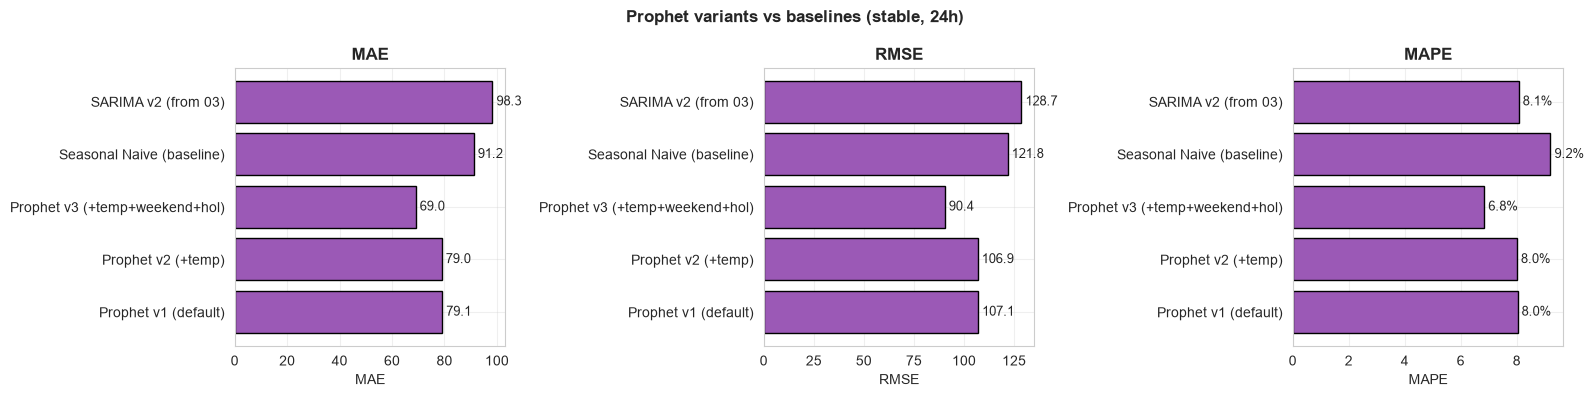


🏆 Best Prophet: Prophet v3 (+temp+weekend+hol) (MAPE = 6.84%)
🥇 Overall best: Prophet v3 (+temp+weekend+hol) (MAPE = 6.84%)


In [7]:
results = pd.DataFrame([
    {"model": "Prophet v1 (default)", "MAE": mae_v1, "RMSE": rmse_v1, "MAPE": mape_v1},
    {"model": "Prophet v2 (+temp)", "MAE": mae_v2, "RMSE": rmse_v2, "MAPE": mape_v2},
    {"model": "Prophet v3 (+temp+weekend+hol)", "MAE": mae_v3, "RMSE": rmse_v3, "MAPE": mape_v3},
    {"model": "Seasonal Naive (baseline)",
     "MAE": mean_absolute_error(y_test.values, y_pred_snaive),
     "RMSE": np.sqrt(mean_squared_error(y_test.values, y_pred_snaive)),
     "MAPE": baseline_mape},
    {"model": "SARIMA v2 (from 03)", "MAE": 98.3, "RMSE": 128.7, "MAPE": 8.07},
])

print(results.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE"]):
    bars = ax.barh(results["model"], results[metric],
                   color="#9b59b6", edgecolor="black")
    ax.set_xlabel(metric)
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)
    for i, v in enumerate(results[metric]):
        unit = "%" if metric == "MAPE" else ""
        ax.text(v, i, f" {v:.1f}{unit}", va="center", fontsize=9)

plt.suptitle("Prophet variants vs baselines (stable, 24h)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04a_prophet_comparison.png", bbox_inches="tight")
plt.show()

# Best САМО сред Prophet
prophet_results = results[results["model"].str.startswith("Prophet")].copy()
best_prophet = prophet_results.loc[prophet_results["MAPE"].idxmin()]
overall_best = results.loc[results["MAPE"].idxmin()]

print(f"\n🏆 Best Prophet: {best_prophet['model']} (MAPE = {best_prophet['MAPE']:.2f}%)")
print(f"🥇 Overall best: {overall_best['model']} (MAPE = {overall_best['MAPE']:.2f}%)")

## 8️⃣ Визуализация — best Prophet vs actual vs snaive

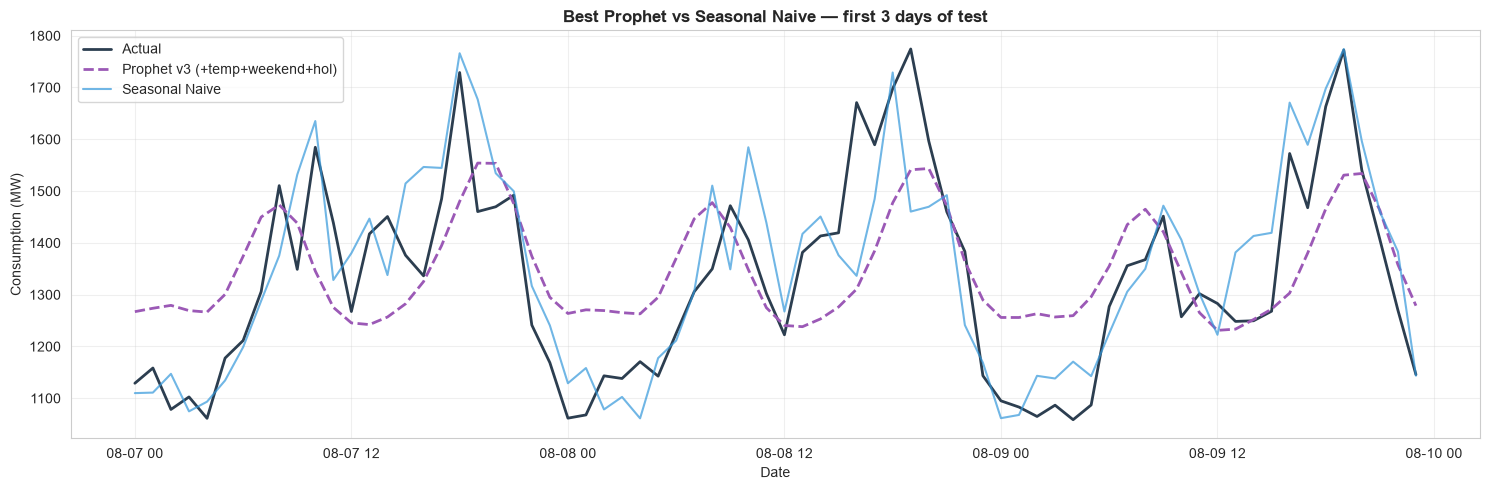

In [8]:
pred_map = {
    "Prophet v1 (default)": y_pred_v1,
    "Prophet v2 (+temp)": y_pred_v2,
    "Prophet v3 (+temp+weekend+hol)": y_pred_v3,
}
forecast_map = {
    "Prophet v1 (default)": forecast_v1,
    "Prophet v2 (+temp)": forecast_v2,
    "Prophet v3 (+temp+weekend+hol)": forecast_v3,
}

y_pred_best = pred_map[best_prophet["model"]]
forecast_best = forecast_map[best_prophet["model"]]
model_best = {
    "Prophet v1 (default)": model_v1,
    "Prophet v2 (+temp)": model_v2,
    "Prophet v3 (+temp+weekend+hol)": model_v3,
}[best_prophet["model"]]

n_plot = min(3 * 24, len(test_p))

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test_p["ds"][:n_plot], y_test.values[:n_plot],
        label="Actual", color="#2c3e50", lw=2)
ax.plot(test_p["ds"][:n_plot], y_pred_best[:n_plot],
        label=f"{best_prophet['model']}", color="#9b59b6", lw=2, ls="--")
ax.plot(test_p["ds"][:n_plot], y_pred_snaive[:n_plot],
        label="Seasonal Naive", color="#3498db", lw=1.5, alpha=0.7)
ax.set_xlabel("Date")
ax.set_ylabel("Consumption (MW)")
ax.set_title(f"Best Prophet vs Seasonal Naive — first {n_plot // 24} days of test")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04b_prophet_forecast.png", bbox_inches="tight")
plt.show()

## 9️⃣ Components на най-добрия Prophet

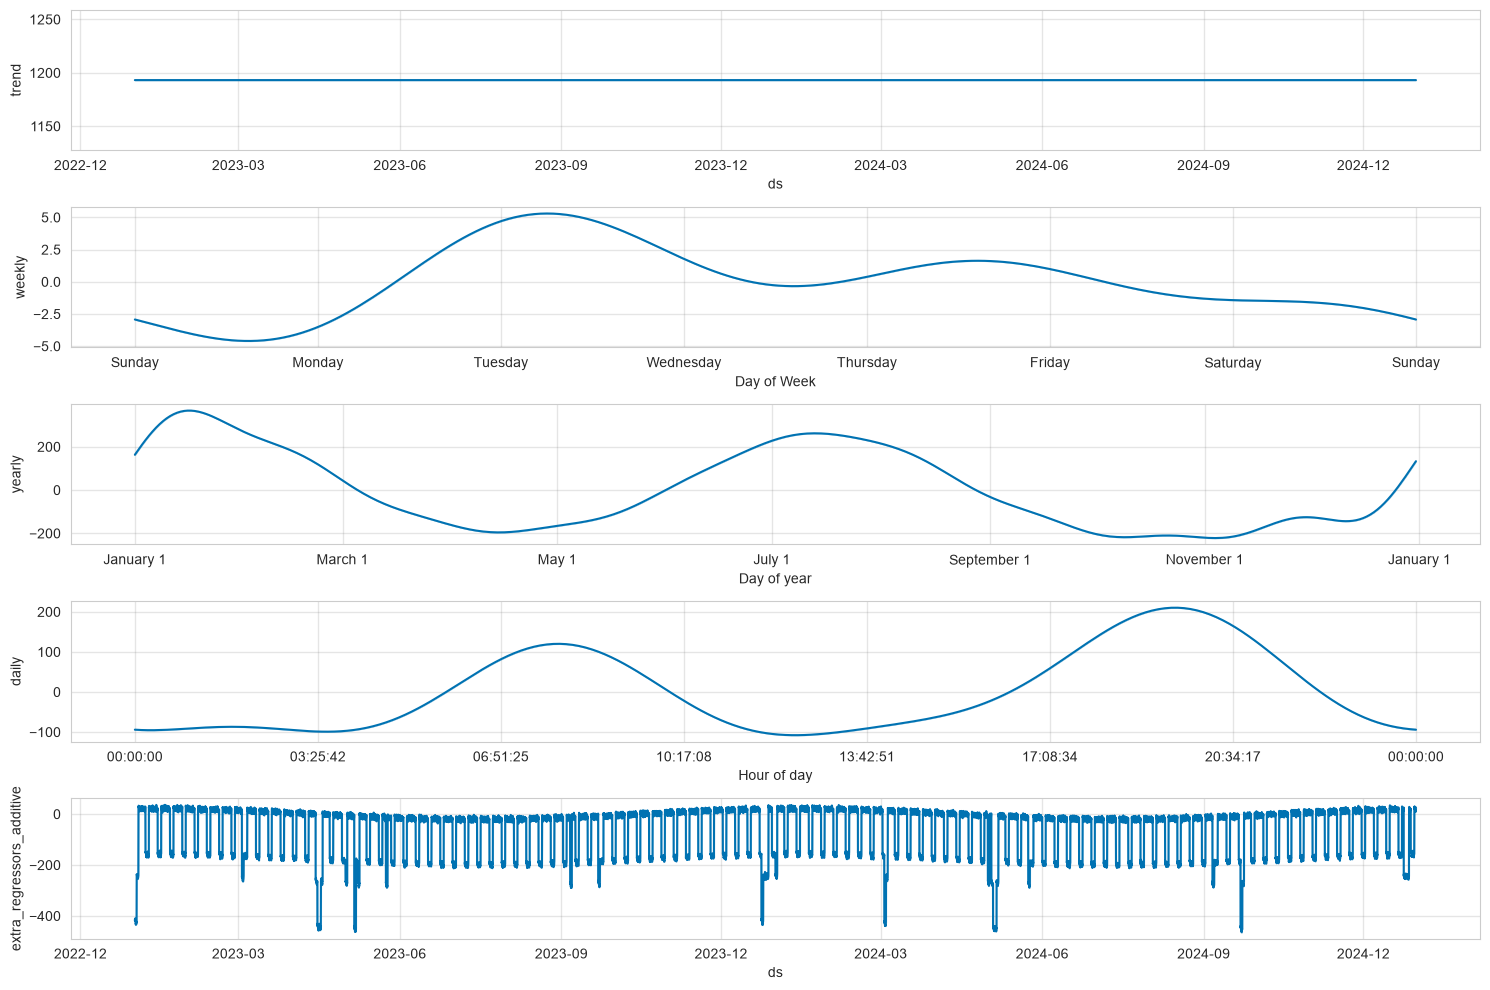

In [9]:
fig = model_best.plot_components(forecast_best)
fig.set_size_inches(15, 10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04c_prophet_components.png", bbox_inches="tight")
plt.show()

## 🔟 Diagnostics (residuals на v3)

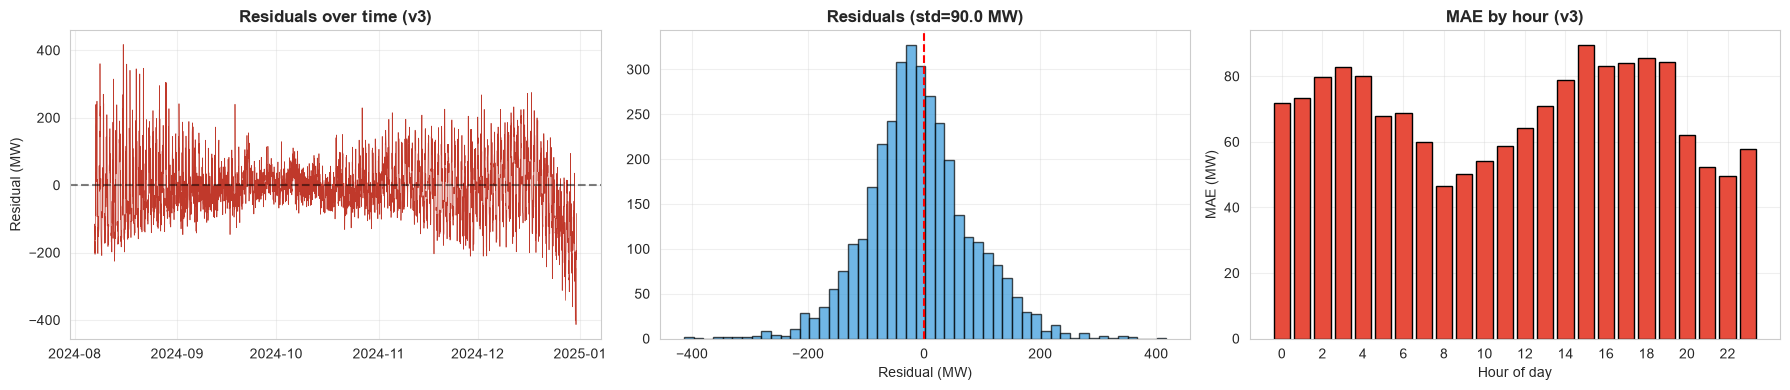

Residual mean: -9.26 MW
Residual std:  89.95 MW
Bias check:    ✅ unbiased


In [10]:
residuals_v3 = y_test.values - y_pred_v3

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(test_p["ds"], residuals_v3, color="#c0392b", lw=0.5)
axes[0].axhline(0, color="black", ls="--", alpha=0.5)
axes[0].set_title("Residuals over time (v3)")
axes[0].set_ylabel("Residual (MW)")
axes[0].grid(alpha=0.3)

axes[1].hist(residuals_v3, bins=50, color="#3498db",
             edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title(f"Residuals (std={residuals_v3.std():.1f} MW)")
axes[1].set_xlabel("Residual (MW)")

test_hours = test_p["ds"].dt.hour.values
hourly_err = pd.Series(np.abs(residuals_v3)).groupby(test_hours).mean()
axes[2].bar(hourly_err.index, hourly_err.values,
            color="#e74c3c", edgecolor="black")
axes[2].set_xlabel("Hour of day")
axes[2].set_ylabel("MAE (MW)")
axes[2].set_title("MAE by hour (v3)")
axes[2].set_xticks(range(0, 24, 2))
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04d_prophet_diagnostics.png", bbox_inches="tight")
plt.show()

print(f"Residual mean: {residuals_v3.mean():+.2f} MW")
print(f"Residual std:  {residuals_v3.std():.2f} MW")
print(f"Bias check:    {'⚠️ BIASED' if abs(residuals_v3.mean()) > 10 else '✅ unbiased'}")

## 1️⃣1️⃣ Save best Prophet model + predictions

In [11]:
model_path = MODELS_DIR / "prophet_stable.pkl"
with open(model_path, "wb") as f:
    pickle.dump({
        "model_name": best_prophet["model"],
        "model": model_best,
        "fit_mape": best_prophet["MAPE"],
        "baseline_mape": baseline_mape,
    }, f)
print(f"💾 Saved: {model_path}")
print(f"   Model: {best_prophet['model']}")
print(f"   MAPE:  {best_prophet['MAPE']:.2f}%")

pred_df = pd.DataFrame({
    "timestamp": test_p["ds"],
    "actual": y_test.values,
    "prophet_best": y_pred_best,
    "prophet_v1": y_pred_v1,
    "prophet_v2": y_pred_v2,
    "prophet_v3": y_pred_v3,
    "snaive": y_pred_snaive[: len(y_pred_best)],
})
pred_path = MODELS_DIR / "prophet_stable_predictions.parquet"
pred_df.to_parquet(pred_path, compression="snappy")
print(f"💾 Saved: {pred_path}")

💾 Saved: D:\CUDA\Python\ClasicML\GridForecast\models\prophet_stable.pkl
   Model: Prophet v3 (+temp+weekend+hol)
   MAPE:  6.84%
💾 Saved: D:\CUDA\Python\ClasicML\GridForecast\models\prophet_stable_predictions.parquet


## 1️⃣2️⃣ Заключение

In [12]:
print("=" * 70)
print("ЗАКЛЮЧЕНИЕ (04_prophet.ipynb)")
print("=" * 70)
print()
print(f"Prophet v1 (default):           MAPE = {mape_v1:.2f}%")
print(f"Prophet v2 (+temp):             MAPE = {mape_v2:.2f}%")
print(f"Prophet v3 (+temp+weekend+hol): MAPE = {mape_v3:.2f}%")
print(f"Seasonal Naive (baseline):      MAPE = {baseline_mape:.2f}%")
print(f"SARIMA v2 (from 03):            MAPE = 8.07%")
print()
print(f"🏆 Best Prophet: {best_prophet['model']} ({best_prophet['MAPE']:.2f}%)")
print(f"🥇 Overall best: {overall_best['model']} ({overall_best['MAPE']:.2f}%)")
print()
print("Сравнение с SARIMA (от 03):")
print(f"  SARIMA v2:    MAPE = 8.07%")
print(f"  Prophet best: MAPE = {best_prophet['MAPE']:.2f}%")
improvement = (8.07 - best_prophet['MAPE']) / 8.07 * 100
print(f"  Подобрение: {improvement:+.1f}%")
print()
print("Изводи:")
print("  - growth='flat' — без trend extrapolation (главен проблем)")
print("  - seasonality_mode='additive' — без compounding")
print("  - yearly_seasonality=True — годишен цикъл (въпреки warning)")
print("  - temperature_c → additive regressor (малък ефект)")
print("  - is_weekend/is_holiday → additive binary regressors (голям ефект)")
print("  - Опитани: linear growth (29%), yearly='auto' (18%) → по-лоши")
print("=" * 70)

ЗАКЛЮЧЕНИЕ (04_prophet.ipynb)

Prophet v1 (default):           MAPE = 8.03%
Prophet v2 (+temp):             MAPE = 8.01%
Prophet v3 (+temp+weekend+hol): MAPE = 6.84%
Seasonal Naive (baseline):      MAPE = 9.20%
SARIMA v2 (from 03):            MAPE = 8.07%

🏆 Best Prophet: Prophet v3 (+temp+weekend+hol) (6.84%)
🥇 Overall best: Prophet v3 (+temp+weekend+hol) (6.84%)

Сравнение с SARIMA (от 03):
  SARIMA v2:    MAPE = 8.07%
  Prophet best: MAPE = 6.84%
  Подобрение: +15.2%

Изводи:
  - growth='flat' — без trend extrapolation (главен проблем)
  - seasonality_mode='additive' — без compounding
  - yearly_seasonality=True — годишен цикъл (въпреки warning)
  - temperature_c → additive regressor (малък ефект)
  - is_weekend/is_holiday → additive binary regressors (голям ефект)
  - Опитани: linear growth (29%), yearly='auto' (18%) → по-лоши
